# Predikcija cene polovnih automobila
**Luka Krestalica — Task 4**

Predviđamo `priceUSD` iz karakteristika automobila. Sveska prikazuje EDA, odluke o čišćenju, izvedene karakteristike, pretprocesiranje, poređenje i tumačenje grešaka. Izvorni `cars.csv` ostaje neizmenjen u `data/`.

Otvoriti svesku iz projekta, instalirati `requirements.txt` i pokrenuti sve ćelije. Podrazumevano čitamo rezultate izvršenog treninga. Za ponavljanje treninga postaviti `RETRAIN=True` u ćeliji poređenja ili pokrenuti `python -m src.model_comparison`. Ako rezultati ne postoje, sveska ih sama kreira.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data_cleaning import load_clean_data, clean_features, TARGET, CATEGORICAL
from src.feature_engineering import CarFeatures
from src.data_preprocessing import make_preprocessor
from src.model_comparison import run_comparison
from src.model_evaluation import evaluate_saved
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
raw, clean, cleaning = load_clean_data(ROOT / 'data/cars.csv')

## 1. Osnovni pregled
Proveravamo dimenzije, tipove, nedostajuća polja, numeričke raspone i kategorije. Oznake marke i modela su tekst i ne dobijaju proizvoljan numerički redosled.

In [2]:
print('Dimenzije:', raw.shape)
display(raw.head())
raw.info()
display(raw.isna().sum().rename('Nedostaje').to_frame())
display(raw.describe().T)
display(raw[CATEGORICAL].nunique().rename('Broj različitih vrednosti').to_frame())
for col in ['condition','fuel_type','transmission','drive_unit','segment']:
    print('\n', col)
    print(raw[col].value_counts(dropna=False).to_string())

Dimenzije: (56244, 12)
<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB

 condition
condition
with mileage    55278
with damage       512
for parts         454

 fuel_type
fuel_type
petrol     

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


,Nedostaje
make,0
model,0
priceUSD,0
year,0
condition,0
mileage(kilometers),0
fuel_type,0
volume(cm3),47
color,0
transmission,0


,count,mean,std,min,25%,50%,75%,max
priceUSD,56244.0,7415.456440,8316.959261,48.0,2350.0,5350.0,9807.5,235235.0
year,56244.0,2003.454840,8.144247,1910.0,1998.0,2004.0,2010.0,2019.0
mileage(kilometers),56244.0,244395.631020,321030.668382,0.0,137000.0,228500.0,310000.0,9999999.0
volume(cm3),56197.0,2104.860615,959.201633,500.0,1600.0,1996.0,2300.0,20000.0


,Broj različitih vrednosti
make,96
model,1034
condition,3
fuel_type,3
color,13
transmission,2
drive_unit,4
segment,9


## 2. Cena, ekstremi i veze sa karakteristikama
Cilj je cena u USD; MSE će zato biti u USD². Cena ima desni rep, pa prikazujemo i logaritamsku skalu. Niske cene mogu predstavljati oštećene automobile, a visoke luksuzna vozila: ne brišemo ih samo zato što su ekstremne.

Godine idu do 2019. i skup nema datum oglasa. Ne zaključujemo da su ove cene današnje tržišne cene. Godina 2026 služi kao fiksna referenca za izvedenu starost, ne kao datum opažanja cene.

Kilometraža iznad 2 miliona: 231
Motor iznad 10.000 cm³: 86


,Cena USD
0.000,48.000
0.001,166.486
0.010,333.000
0.250,2350.000
0.500,5350.000
0.750,9807.500
0.950,20000.000
0.990,39728.500
0.999,86975.700
1.000,235235.000


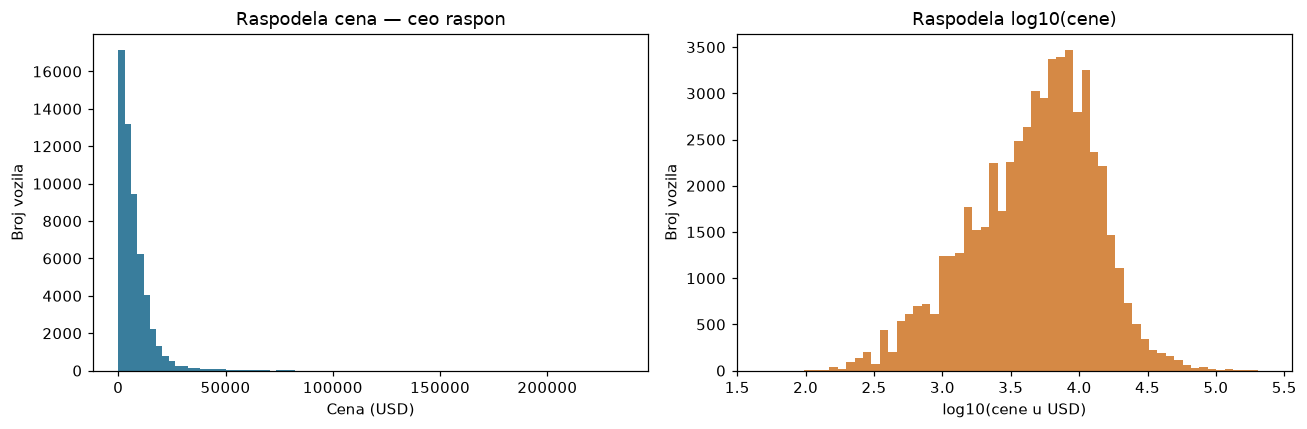

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
20787,bentley,continental-gt,235235,2018,with mileage,29000.0,petrol,6000.0,white,auto,all-wheel drive,NaN
16430,bentley,bentayga,195000,2016,with mileage,72000.0,petrol,6000.0,other,auto,all-wheel drive,NaN
35457,bentley,mulsanne,190141,2014,with mileage,36500.0,petrol,6750.0,purple,auto,rear drive,NaN
16428,bentley,bentayga,183848,2016,with mileage,22000.0,petrol,6000.0,silver,auto,all-wheel drive,NaN
16429,bentley,bentayga,170477,2016,with mileage,74100.0,petrol,6000.0,other,auto,all-wheel drive,NaN


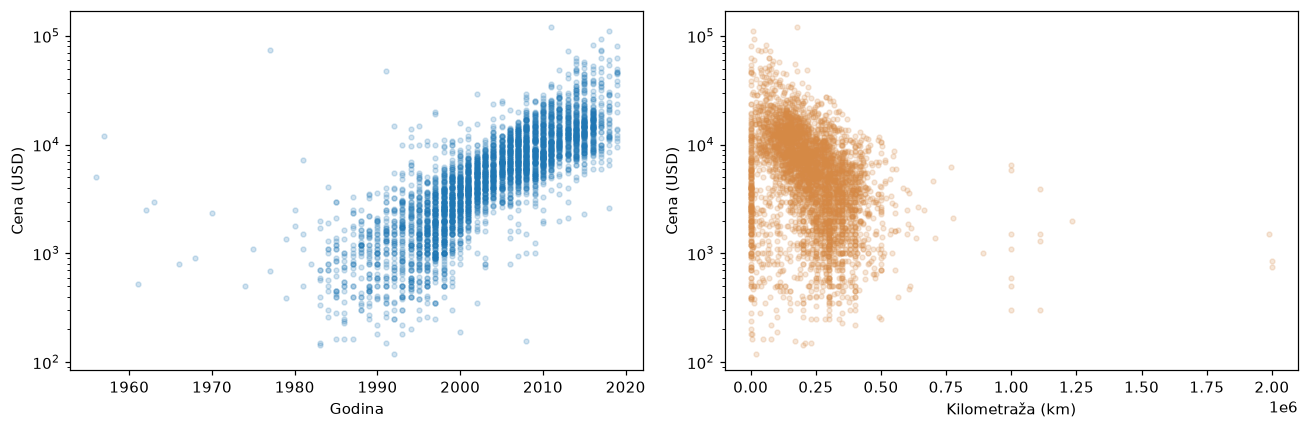

In [3]:
display(raw['priceUSD'].quantile([0,.001,.01,.25,.5,.75,.95,.99,.999,1]).rename('Cena USD').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw.priceUSD, bins=80, color='#397d9c'); axes[0].set_title('Raspodela cena — ceo raspon')
axes[0].set_xlabel('Cena (USD)'); axes[0].set_ylabel('Broj vozila')
axes[1].hist(np.log10(raw.priceUSD), bins=60, color='#d58945'); axes[1].set_title('Raspodela log10(cene)')
axes[1].set_xlabel('log10(cene u USD)'); axes[1].set_ylabel('Broj vozila')
plt.tight_layout(); plt.show()
print('Kilometraža iznad 2 miliona:', int((raw['mileage(kilometers)'] > 2000000).sum()))
print('Motor iznad 10.000 cm³:', int((raw['volume(cm3)'] > 10000).sum()))
display(raw.nlargest(5, 'priceUSD'))
sample = clean.sample(min(4000, len(clean)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sample.year, sample.priceUSD, alpha=.2, s=10)
axes[0].set_xlabel('Godina'); axes[0].set_ylabel('Cena (USD)'); axes[0].set_yscale('log')
axes[1].scatter(sample.mileage_km, sample.priceUSD, alpha=.2, s=10, color='#d58945')
axes[1].set_xlabel('Kilometraža (km)'); axes[1].set_ylabel('Cena (USD)'); axes[1].set_yscale('log')
plt.tight_layout(); plt.show()

## 3. Pravila čišćenja
Kolone `mileage(kilometers)` i `volume(cm3)` menjaju naziv u `mileage_km` i `engine_cm3`. Tekst se standardizuje u mala slova bez spoljašnjih razmaka. Numeričke vrednosti parsiraju se uz pretvaranje nečitljivih vrednosti u NaN.

Nedostajuća, nepozitivna ili beskonačna ciljna cena odbacuje se. Potpuni duplikati nakon standardizacije uklanjaju se. Sumnjive karakteristike pretvaraju se u NaN, bez brisanja cele ponude: godina van 1886–2026 ili necela godina, kilometraža van 0–2.000.000 km, motor van 100–10.000 cm³. To su eksplicitne granice kvaliteta za ovaj projekat, ne tvrdnja da svaka vrednost van granice mora biti netačna.

Nedostajuće numeričke vrednosti kasnije popunjava medijana treninga, uz indikatore nedostajanja. Nedostajuće kategorije dobijaju oznaku `unknown`. Cena se nikada ne imputira.

In [4]:
print(json.dumps(cleaning, ensure_ascii=False, indent=2))
display(clean.head())
display(clean.isna().sum().rename('Nedostaje pre imputacije').to_frame())

{
  "raw_rows": 56244,
  "raw_columns": 12,
  "missing_before": {
    "make": 0,
    "model": 0,
    "priceUSD": 0,
    "year": 0,
    "condition": 0,
    "mileage(kilometers)": 0,
    "fuel_type": 0,
    "volume(cm3)": 47,
    "color": 0,
    "transmission": 0,
    "drive_unit": 1905,
    "segment": 5291
  },
  "invalid_target_rows": 0,
  "duplicates_removed": 88,
  "clean_rows": 56156,
  "missing_features_after_rules": {
    "year": 0,
    "mileage_km": 231,
    "engine_cm3": 133,
    "make": 0,
    "model": 0,
    "condition": 0,
    "fuel_type": 0,
    "color": 0,
    "transmission": 0,
    "drive_unit": 1905,
    "segment": 5291
  },
  "reference_year": 2026
}


,year,mileage_km,engine_cm3,make,model,condition,fuel_type,color,transmission,drive_unit,segment,priceUSD
0,2008.0,162000.0,1500.0,mazda,2,with mileage,petrol,burgundy,mechanics,front-wheel drive,b,5500
1,2009.0,120000.0,1300.0,mazda,2,with mileage,petrol,black,mechanics,front-wheel drive,b,5350
2,2009.0,61000.0,1500.0,mazda,2,with mileage,petrol,silver,auto,front-wheel drive,b,7000
3,2003.0,265000.0,1400.0,mazda,2,with mileage,diesel,white,mechanics,front-wheel drive,b,3300
4,2008.0,97183.0,1400.0,mazda,2,with mileage,diesel,gray,mechanics,front-wheel drive,b,5200


,Nedostaje pre imputacije
year,0
mileage_km,229
engine_cm3,133
make,0
model,0
condition,0
fuel_type,0
color,0
transmission,0
drive_unit,1904


## 4. Inženjering karakteristika
`car_age = 2026 - year` daje starost prema fiksnoj referenci. `mileage_per_year` deli kilometražu tom starošću (najmanji delilac je 1), ali bez datuma oglasa nije stvarno izmerena godišnja kilometraža. `engine_volume_liters` pretvara cm³ u litre. `is_high_mileage` označava najmanje 200.000 km. `brand_model` povezuje marku sa modelom, jer isti naziv modela kod različitih marki ne mora značiti isto vozilo.

Nepoznata starost/kilometraža ostaje NaN do imputacije. Izvorna godina i cm³ ne ponavljaju se uz svoje linearne transformacije u završnim numeričkim ulazima.

In [5]:
engineered = CarFeatures().transform(clean.drop(columns=TARGET))
display(engineered[['year','car_age','mileage_km','mileage_per_year','engine_volume_liters','is_high_mileage','brand_model']].head(10))
display(engineered[['car_age','mileage_per_year','engine_volume_liters']].describe().T)

,year,car_age,mileage_km,mileage_per_year,engine_volume_liters,is_high_mileage,brand_model
0,2008.0,18.0,162000.0,9000.000000,1.5,0.0,mazda | 2
1,2009.0,17.0,120000.0,7058.823529,1.3,0.0,mazda | 2
2,2009.0,17.0,61000.0,3588.235294,1.5,0.0,mazda | 2
3,2003.0,23.0,265000.0,11521.739130,1.4,1.0,mazda | 2
4,2008.0,18.0,97183.0,5399.055556,1.4,0.0,mazda | 2
5,2005.0,21.0,150000.0,7142.857143,1.3,0.0,mazda | 2
6,2008.0,18.0,112000.0,6222.222222,1.3,0.0,mazda | 2
7,2009.0,17.0,95000.0,5588.235294,1.5,0.0,mazda | 2
8,2010.0,16.0,93804.0,5862.750000,1.5,0.0,mazda | 2
9,2008.0,18.0,196511.0,10917.277778,1.5,0.0,mazda | 2


,count,mean,std,min,25%,50%,75%,max
car_age,56156.0,22.543326,8.145465,7.0,16.000000,22.000,28.000000,116.000000
mileage_per_year,55927.0,10290.431739,5097.317874,0.0,7692.307692,10500.000,13181.818182,145833.333333
engine_volume_liters,56023.0,2.080446,0.721683,0.5,1.600000,1.995,2.300000,10.000000


## 5. Pretprocesiranje i podela
`SimpleImputer`, `StandardScaler` i `OneHotEncoder` nalaze se u Pipeline-u. Statistike i rečnik kategorija uče se samo na treningu. Retke oznake (manje od 10 pojavljivanja) grupišu se, uz najviše 150 izlaznih kategorija po koloni, a nove oznake ne izazivaju grešku.

Grupna podela približno 60/20/20 sprečava da identični atributi vozila sa različitim cenama pređu između treninga, validacije i testa. Seme je 42. Time ne možemo garantovati razdvajanje različitih oglasa za isto fizičko vozilo jer nema VIN identifikatora.

Na validaciji biramo najniži MAE (RMSE razrešava izjednačenje). Izbor se zaključava pre testiranja. Sva tri algoritma i medijanska referenca zatim se obučavaju na istom razvojnome skupu (trening + validacija) i ocenjuju na istom testu.

In [6]:
display(make_preprocessor())
RETRAIN = False
if RETRAIN or not (ROOT / 'reports/metadata.json').exists():
    run_comparison()
metadata = json.loads((ROOT / 'reports/metadata.json').read_text())
validation = pd.read_csv(ROOT / 'reports/validation_metrics.csv')
test_metrics = pd.read_csv(ROOT / 'reports/test_metrics.csv')
print('Veličine skupova:', metadata['split_sizes'])
print('Izbor prema validaciji:', metadata['selected_model'])
display(validation.round(3))
display(test_metrics.round(3))

Veličine skupova: {'train': 33693, 'validation': 11231, 'test': 11232, 'saved_model_training': 44924}
Izbor prema validaciji: Random forest


Pipeline(steps=[('features', CarFeatures()),
                ('columns',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['car_age', 'mileage_km',
                                                   'mileage_per_year',
                                                   'engine_volume_liters',
                                                   'is_high_mileage']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 max_categories=150,
                                                                                 min_frequency=10))]),
                                                  ['make', 'model',
                                                   'brand_model', 'condition',
                                                   'fuel_type', 'color',
                                                   'transmission', 'drive_unit',
                                                   'segment'])]))])

,model,MAE_USD,MSE_USD2,RMSE_USD,R2,seconds
0,Median baseline,4801.364,6.535287e+07,8084.112,-0.062,0.514
1,Ridge regression,2285.494,2.070323e+07,4550.080,0.664,0.508
2,Decision tree,1366.901,9.657860e+06,3107.710,0.843,1.482
3,Random forest,1167.039,6.848303e+06,2616.926,0.889,32.796


,model,MAE_USD,MSE_USD2,RMSE_USD,R2
0,Median baseline,4969.821,8.007467e+07,8948.445,-0.057
1,Ridge regression,2316.518,2.832187e+07,5321.829,0.626
2,Decision tree,1361.012,1.153730e+07,3396.660,0.848
3,Random forest,1160.833,8.324476e+06,2885.217,0.890


## 6. Poređenje i tumačenje metrika
Ridge je regularizovana linearna regresija. Stablo hvata nelinearne odnose; Random Forest kombinuje više stabala radi stabilnije predikcije. Medijanska referenca ne koristi karakteristike i pokazuje koliko model doprinosi u odnosu na jednostavno pogađanje.

MAE je prosečna apsolutna greška u dolarima. RMSE jače kažnjava velike greške. MSE je kvadratna greška u USD². R² poredi objašnjenu varijaciju sa predikcijom proseka; nije procenat tačno pogođenih cena. Negativne predikcije odsecamo na 0 na isti način tokom evaluacije i upotrebe.

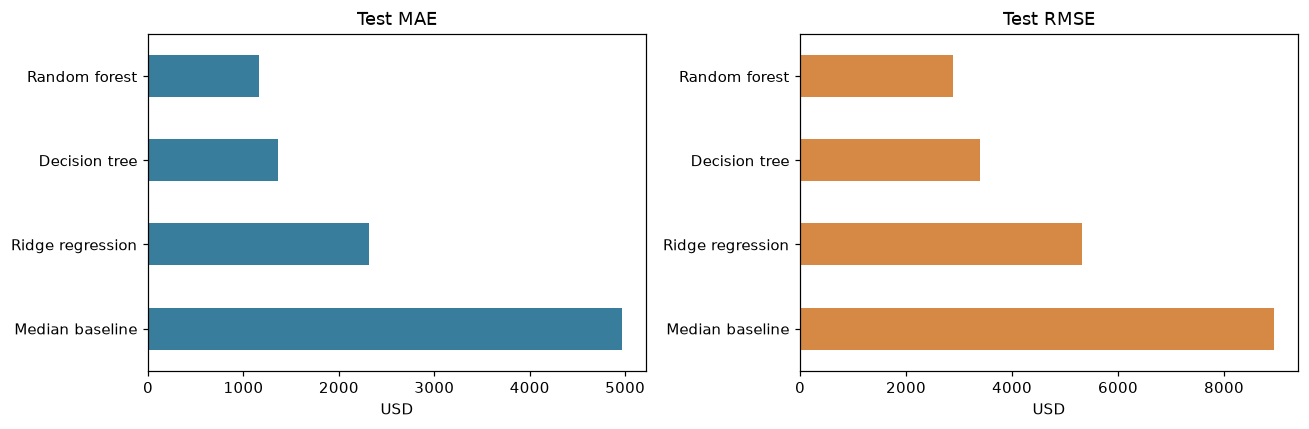

,actual_price_USD,predicted_price_USD,absolute_error_USD
0,5350,4775.52,574.48
1,6400,5216.17,1183.83
2,6132,5247.62,884.38
3,5400,4644.70,755.30
4,5300,4650.05,649.95
5,5950,4818.86,1131.14
6,3500,3260.11,239.89
7,6500,5384.53,1115.47
8,6700,7208.29,508.29
9,4754,5084.81,330.81


,make,model,year,actual_price_USD,predicted_price_USD,absolute_error_USD
3207,bentley,bentayga,2016.0,195000,97008.03,97991.97
3820,porsche,cayenne,2018.0,170000,84909.92,85090.08
8476,land-rover,range-rover,2018.0,118000,37179.32,80820.68
3206,bentley,bentayga,2016.0,183848,115923.81,67924.19
6724,mercedes-benz,maybach,2015.0,125000,62442.15,62557.85
9806,volkswagen,touareg,2019.0,25700,76665.76,50965.76
10144,mercedes-benz,v-klass,2019.0,95898,50020.92,45877.08
5194,mercedes-benz,g-klass,2015.0,104000,65523.59,38476.41


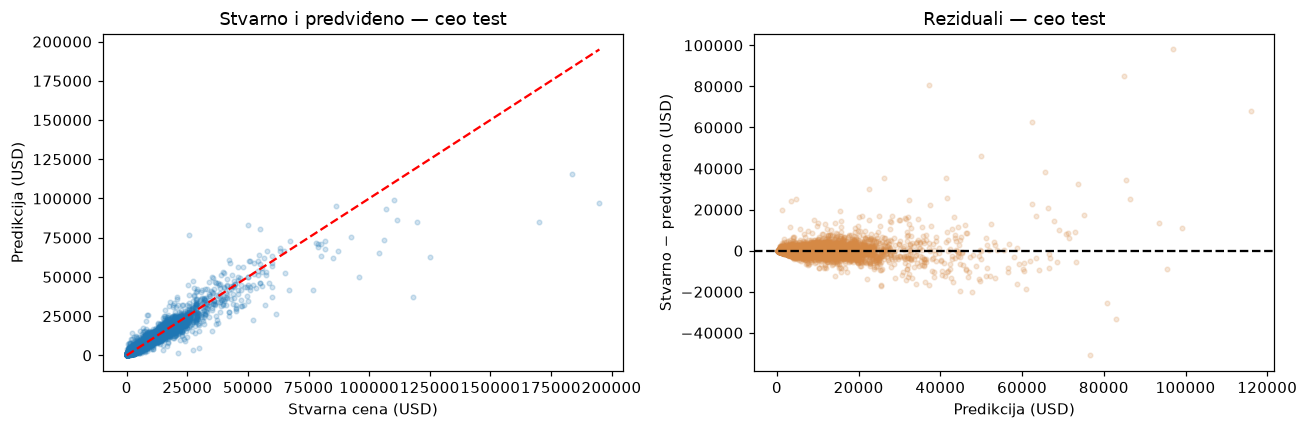

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_metrics.set_index('model')['MAE_USD'].plot.barh(ax=axes[0], color='#397d9c')
axes[0].set_title('Test MAE'); axes[0].set_xlabel('USD'); axes[0].set_ylabel('')
test_metrics.set_index('model')['RMSE_USD'].plot.barh(ax=axes[1], color='#d58945')
axes[1].set_title('Test RMSE'); axes[1].set_xlabel('USD'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()
predictions = pd.read_csv(ROOT / 'reports/test_predictions.csv')
display(predictions[['actual_price_USD','predicted_price_USD','absolute_error_USD']].head(12).round(2))
display(predictions.nlargest(8,'absolute_error_USD')[['make','model','year','actual_price_USD','predicted_price_USD','absolute_error_USD']].round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(predictions.actual_price_USD,predictions.predicted_price_USD,alpha=.2,s=9)
limit=max(predictions.actual_price_USD.max(),predictions.predicted_price_USD.max())
axes[0].plot([0,limit],[0,limit],'r--'); axes[0].set_xlabel('Stvarna cena (USD)'); axes[0].set_ylabel('Predikcija (USD)')
axes[0].set_title('Stvarno i predviđeno — ceo test')
residuals=predictions.actual_price_USD-predictions.predicted_price_USD
axes[1].scatter(predictions.predicted_price_USD,residuals,alpha=.2,s=9,color='#d58945')
axes[1].axhline(0,color='black',linestyle='--'); axes[1].set_xlabel('Predikcija (USD)'); axes[1].set_ylabel('Stvarno − predviđeno (USD)')
axes[1].set_title('Reziduali — ceo test')
plt.tight_layout(); plt.show()

## 7. Provera sačuvanog modela i zaključak
Sačuvan je ceo Pipeline, obučen na razvojnih približno 80% podataka. Nema ponovnog treniranja na testu. Zato `model_evaluation.py` može ponoviti test metrike i proveriti stvarni sačuvani fajl. Primer Golf vozila služi za demonstraciju: 9.990 USD iz teksta zadatka nije cilj koji model treba ručno da oponaša.

In [8]:
rechecked = evaluate_saved()
selected = test_metrics.loc[test_metrics.model.eq(metadata['selected_model'])].iloc[0]
assert np.isclose(rechecked['MAE_USD'], selected['MAE_USD'])
print('Primer iz zadatka:', metadata['example'])
print(f"Predikcija: {metadata['example_prediction_USD']:.2f} USD")
display(Markdown(f"**Izabran je {metadata['selected_model']}** prema validacionom MAE. Na testu ima "
                f"**MAE {selected['MAE_USD']:.2f} USD**, RMSE {selected['RMSE_USD']:.2f} USD, "
                f"MSE {selected['MSE_USD2']:.2f} USD² i R² {selected['R2']:.4f}. "
                "MAE predstavlja prosečnu grešku za ovaj test skup, ne garantovan raspon za pojedinačni automobil."))

{
  "MAE_USD": 1160.8326197470112,
  "MSE_USD2": 8324475.907887464,
  "RMSE_USD": 2885.2167869828195,
  "R2": 0.8900648325861467
}
Primer iz zadatka: {'make': 'volkswagen', 'model': 'golf', 'year': 2014, 'condition': 'with mileage', 'mileage(kilometers)': 180000, 'fuel_type': 'diesel', 'volume(cm3)': 1600, 'color': 'black', 'transmission': 'mechanics', 'drive_unit': 'front-wheel drive', 'segment': 'C'}
Predikcija: 12411.41 USD


**Izabran je Random forest** prema validacionom MAE. Na testu ima **MAE 1160.83 USD**, RMSE 2885.22 USD, MSE 8324475.91 USD² i R² 0.8901. MAE predstavlja prosečnu grešku za ovaj test skup, ne garantovan raspon za pojedinačni automobil.

## Ograničenja i sledeći korak
Ekstremne, retke i kolekcionarske automobile teže je proceniti, što se vidi iz najvećih grešaka. Cena može zavisiti od opreme, oštećenja, održavanja, lokacije i datuma oglasa kojih nema u ulazu. Skup ne potvrđuje ostvarene prodajne cene. Bez datuma oglasa ne može se ispitati vremenska generalizacija niti tvrditi da model meri aktuelno tržište.

Sledeća verzija treba novije i potvrđene podatke, vremenski test, više primera retkih modela i proveru parametara kroz unakrsnu validaciju na treningu. Referentna godina je fiksirana radi ponovljivosti; njena promena zahteva ponovno treniranje.

Dokumentacija: [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html), [MAE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html).